In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [3]:
transect = pd.read_csv('../data/groundwater/well_transect_profile.csv')
transect_A = pd.read_csv('../data/groundwater/wellA_transect_profile.csv')

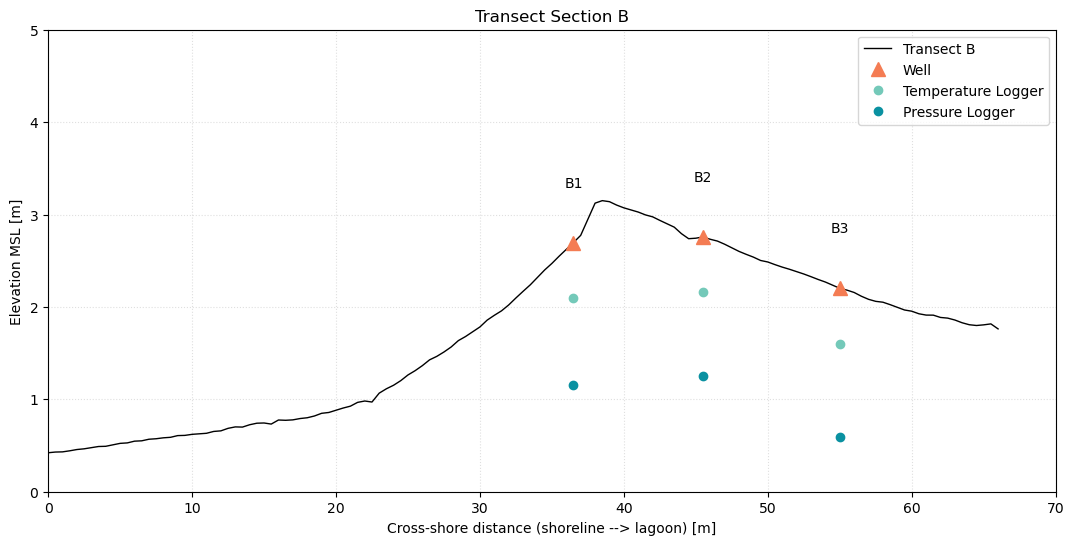

In [4]:
x = transect['distance_m']
mon = transect['Monday']
tues = transect['Tuesday']
wed = transect['Wednesday']

avg = np.zeros(shape=(len(x), 2))
avg[:, 0] = x

for i in range(len(transect)):
    avg[i, 1] = (mon[i] + tues[i] + wed[i]) / 3

wells_x = [36.5, 45.5, 55.0]
aboveground = [0.400, 0.442, 0.334]

wells_y = np.zeros(len(wells_x))
temp_y = np.zeros(len(wells_x))
diver_y = np.zeros(len(wells_x))

for i in range(len(wells_x)):
    wells_y[i] = avg[avg[:, 0] == wells_x[i]][0, 1]
    temp_y[i] = wells_y[i] - 0.6
    diver_y[i] = wells_y[i] - (2.044 - aboveground[i] - 0.1)

plt.figure(figsize=(13, 6))
plt.title('Transect Section B')
plt.xlim(0, 70)
plt.ylim(0, 5)
# plt.plot(x, mon, label='Monday')
# plt.plot(x, tues, label='Tuesday')
# plt.plot(x, wed, label='Wednesday')
plt.plot(x, avg[:, 1], label='Transect B', color='k', lw=1)

well_labels = ['B1', 'B2', 'B3']

for i in range(len(wells_x)):
    plt.plot(wells_x[i], wells_y[i], '^', color='#f47c53', markersize=10, label='Well' if i == 0 else '_nolegend_')
    plt.plot(wells_x[i], temp_y[i], 'o', color='#74c9b9', label='Temperature Logger' if i == 0 else '_nolegend_')
    plt.plot(wells_x[i], diver_y[i], 'o', color='#0a91a1', label='Pressure Logger' if i == 0 else '_nolegend_')
    plt.text(wells_x[i], wells_y[i] + 0.6, well_labels[i], ha='center')

plt.ylabel('Elevation MSL [m]')
plt.xlabel('Cross-shore distance (shoreline --> lagoon) [m]')
plt.grid('minor', alpha=0.4, ls=':')
plt.legend();



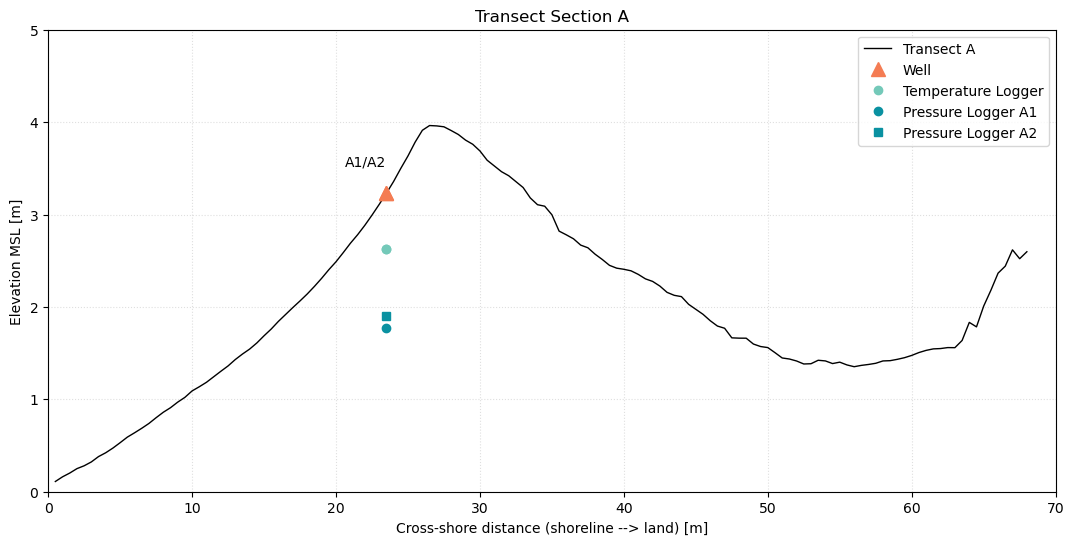

In [5]:
x_A = transect_A['distance_m']
mon_A = transect_A['Monday']
tues_A = transect_A['Tuesday']
wed_A = transect_A['Wednesday']

avg_A = np.zeros(shape=(len(x_A), 2))
avg_A[:, 0] = x_A

for i in range(len(transect_A)):
    avg_A[i, 1] = (mon_A[i] + tues_A[i] + wed_A[i]) / 3

wells_x_A = [23.5, 23.5]
aboveground_A = [0.481, 0.612]

wells_y_A = np.zeros(len(wells_x_A))
temp_y_A = np.zeros(len(wells_x_A))
diver_y_A = np.zeros(len(wells_x_A))

for i in range(len(wells_x_A)):
    wells_y_A[i] = avg_A[avg_A[:, 0] == wells_x_A[i]][0, 1]
    temp_y_A[i] = wells_y_A[i] - 0.6
    diver_y_A[i] = wells_y_A[i] - (2.044 - aboveground_A[i] - 0.1)

plt.figure(figsize=(13, 6))
plt.title('Transect Section A')
plt.xlim(0, 70)
plt.ylim(0, 5)
# plt.plot(x_A, mon_A, label='Monday')
# plt.plot(x_A, tues_A, label='Tuesday')
# plt.plot(x_A, wed_A, label='Wednesday')

plt.plot(x_A, avg_A[:, 1], label='Transect A', color='k', lw=1)

for i in range(len(wells_x_A)):
    plt.plot(wells_x_A[i], wells_y_A[i], '^', color='#f47c53', markersize=10, label='Well' if i == 0 else '_nolegend_')
    plt.plot(wells_x_A[i], temp_y_A[i], 'o', color='#74c9b9', label='Temperature Logger' if i == 0 else '_nolegend_')

plt.plot(wells_x_A[0], diver_y_A[0], 'o', color='#0a91a1', label='Pressure Logger A1')
plt.plot(wells_x_A[1], diver_y_A[1], 's', color='#0a91a1', label='Pressure Logger A2')
plt.text(wells_x_A[0], wells_y_A[0] + 0.3, 'A1/A2', ha='right')
plt.ylabel('Elevation MSL [m]')
plt.xlabel('Cross-shore distance (shoreline --> land) [m]')
plt.grid('minor', alpha=0.4, ls=':')
plt.legend();

